# DBS entrainment vs. recording artifact — two-neuron HH model

**Question.** During 55 Hz DBS, lines appear at **27.5 Hz** and **82.5 Hz** (reported as 28 and
83 Hz) once amplitude reaches ~1 mA. Are they real neural entrainment or artifact from a
noisy stimulator / recording chain?

**Key arithmetic.** 27.5 = $f_s/2$ and 82.5 = $3f_s/2$. Neither is a harmonic of 55 Hz, so a
*linear* artifact cannot make them. These are exactly the two Arnold tongue families that
Duchet et al. (2023) single out as the most prominent higher-order ones: $p{:}1$ (here 1:2) and
$(2p-1){:}2$ (here 3:2).

**The label swap matters.** The trace labelled "DBS OFF" is really **0 mA**. So the sharp 55 Hz
line lives in the *0 mA* condition — stimulator running, zero delivered current. That is a free
measurement: at 0 mA there is no current and therefore no possible neural response, so whatever
sits at 55 Hz there is pure chain contamination, and its height calibrates `clock_gain` below.
The subharmonics do *not* appear at 0 mA — they need ≥1 mA — so they are not telemetry clock
leakage.

**Three candidate mechanisms, and how to tell them apart**

| | peak | amplitude dependence | survives ideal anti-aliasing? |
|---|---|---|---|
| **H1** genuine 1:2 lock of beta, mixing with the 55 Hz artifact → 3:2 | 27.5 / 82.5 Hz, finite linewidth | threshold, then **lost** above an upper boundary | yes |
| **H2** period-2 stimulus (pulse-to-pulse alternation, dropout) | 27.5 / 82.5 Hz, artifact-narrow | monotone in amplitude | yes |
| **H3** aliased harmonics at 250 Hz sampling | **85.0** / 30.0 Hz | monotone | **no** |

**Model.** One E and one I Hodgkin–Huxley neuron (Traub–Miles kinetics), AMPA and GABA_A
conductances, balanced Poisson background, DBS as a charge-balanced pulse train. HH rather than
a phase or Wilson–Cowan model because (a) the candidate "real" mechanism is nonlinear, and
(b) depolarisation block at high amplitude comes for free — a sigmoid cannot lose spiking the
same way.

Sections: 1 stimulus · 2 model · 3 recording chain · 4 metrics · 5 resting state ·
6 charting at 55 Hz · 7 charting at 80 Hz (the decisive test) · 8 summary.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import brian2 as b2
from brian2 import ms, second, mV, nS, nA, pA, uF, cm, um, msiemens, siemens, Hz
from scipy import signal
from dataclasses import dataclass, replace

b2.prefs.codegen.target = 'cython'
b2.prefs.devices.cpp_standalone.extra_make_args_unix = ['-j4']
b2.set_device('cpp_standalone', directory='/tmp/hhdbs_build', build_on_run=True)
b2.BrianLogger.suppress_name('resolution_conflict', 'method_choice')

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25,
                     'font.size': 9})
np.set_printoptions(precision=3, suppress=True)

## 1. Stimulus

Charge-balanced biphasic pulse train. Three separable non-idealities, because they are the
competing explanations for the subharmonics:

- `jitter` — white noise on the stimulation *period* (Duchet's dithering level $\zeta$).
  Destroys higher-order locking; does **not** create a line at $f_s/2$.
- `alternation` — pulse-to-pulse amplitude modulation. Makes the *stimulus itself* period-2,
  putting exact lines at $f_s/2$, $3f_s/2$, ... This is **H2** in its sharpest form.
- `dropout` — randomly missed pulses.

Set all three to zero for an ideal train.

In [2]:
@dataclass
class Stim:
    f_stim: float = 55.0        # Hz
    amp: float = 1.0            # mA
    pulse_width: float = 80e-6  # s (RC+S uses 60-90 us)
    recharge: float = 4.0       # negative phase lasts recharge*pulse_width at -amp/recharge
    jitter: float = 0.0         # zeta, SD of relative period noise
    alternation: float = 0.0    # +-fraction, pulse-to-pulse amplitude modulation
    dropout: float = 0.0        # probability a pulse is skipped
    seed: int = 0


def staircase(t, duration, a_max=10.0, n_steps=10, baseline_frac=0.1):
    """Clinical charting protocol: flat 0 mA baseline, then equal steps up to a_max."""
    t0 = baseline_frac * duration
    step = (duration - t0) / n_steps
    idx = np.floor((np.asarray(t) - t0) / step)
    levels = np.linspace(a_max / n_steps, a_max, n_steps)
    out = np.where(idx < 0, 0.0, levels[np.clip(idx, 0, n_steps - 1).astype(int)])
    return out


def pulse_train(duration, dt, st: Stim, schedule=None):
    """Returns (waveform in mA at step dt, pulse onset times, delivered amplitudes)."""
    n = int(round(duration / dt))
    w_pos = int(round(st.pulse_width / dt))
    if w_pos < 2:
        raise ValueError(f'dt={dt*1e6:.0f} us cannot resolve a {st.pulse_width*1e6:.0f} us pulse')
    w_neg = int(round(st.recharge * st.pulse_width / dt))
    wave = np.zeros(n, dtype=np.float32)

    rng = np.random.default_rng(st.seed)
    k = int(duration * st.f_stim * (1 + 6 * st.jitter)) + 16
    periods = (1 + rng.normal(0, st.jitter, k)) / st.f_stim
    periods = np.clip(periods, (w_pos + w_neg) * dt, None)
    onsets = np.cumsum(periods) - periods[0]
    onsets = onsets[onsets < duration - (w_pos + w_neg) * dt]

    amps = st.amp * (schedule(onsets) if schedule is not None else np.ones_like(onsets))
    if st.alternation:
        amps = amps * (1 + st.alternation * (-1.0) ** np.arange(len(onsets)))
    if st.dropout:
        amps = amps * (rng.random(len(onsets)) > st.dropout)

    for s, a in zip(np.round(onsets / dt).astype(int), amps):
        if a:
            wave[s:s + w_pos] += a
            wave[s + w_pos:s + w_pos + w_neg] -= a * w_pos / w_neg
    return wave, onsets, amps

## 2. Model

Two Traub–Miles HH neurons with conductance-based synapses (E→I AMPA, I→E GABA_A, plus
autapses standing in for $\omega_{EE}$ and $\omega_{II}$), balanced Poisson background, and DBS
injected as a current.

Two details worth flagging:

- Background and recurrent synapses have **separate time constants**, so tuning `tau_gaba`
  (which sets the E–I loop period, i.e. where the resting rhythm sits) does not also change the
  mean background drive. Without this the network flips between I-dominated and E-dominated.
- Stimulation gain scales as $r_{\text{ref}}/r$ — a monopole point source, $V \propto
  I/(4\pi\sigma r)$. With two neurons this is just a scalar, but it is the hook for the network
  version: draw $r$ per neuron and the same code works unchanged.

Stimulation targets the I cell by default (Sermon et al.), with a smaller direct effect on E.

In [3]:
@dataclass
class Cfg:
    # integration
    dt: float = 0.02            # ms  (must resolve the 80 us pulse)
    record_dt: float = 0.1      # ms  -> 10 kHz "analog" record
    # membrane (Traub-Miles HH)
    area: float = 20000.        # um^2
    El: float = -60.; EK: float = -90.; ENa: float = 50.; VT: float = -63.
    # synapses
    Ee: float = 0.; Ei: float = -80.
    tau_ampa: float = 2.;  tau_gaba: float = 26.     # ms, recurrent
    tau_ampa_bg: float = 2.; tau_gaba_bg: float = 10.  # ms, background
    w_EI: float = 4.;  w_IE: float = 45.; w_EE: float = 1.; w_II: float = 3.   # nS
    d_EI: float = 5.;  d_IE: float = 5.                                        # ms
    # background
    bg_N_e: int = 800; bg_rate_e: float = 10.; bg_w_e: float = 0.3
    bg_N_i: int = 200; bg_rate_i: float = 10.; bg_w_i: float = 1.2
    I_dc_E: float = 250.; I_dc_I: float = 190.       # pA
    # stimulation coupling
    I_per_mA: float = 5.        # nA per mA at the reference distance
                                # (25 drives the E cell into block by 2 mA,
                                #  which flattens the whole 2-10 mA range)
    r_ref: float = 2000.; r_E: float = 2000.; r_I: float = 2000.   # um
    gain_E: float = 0.3; gain_I: float = 1.0
    seed: int = 1


EQS = """
dv/dt = (gl*(El-v) + (ge_rec+ge_ext)*(Ee-v) + (gi_rec+gi_ext)*(Ei-v)
         - gNa*(m*m*m)*h*(v-ENa) - gKd*(n*n*n*n)*(v-EK) + I_dc + stim_gain*dbs(t))/Cm : volt
dm/dt = alpha_m*(1-m) - beta_m*m : 1
dn/dt = alpha_n*(1-n) - beta_n*n : 1
dh/dt = alpha_h*(1-h) - beta_h*h : 1
alpha_m = 0.32*(mV**-1)*(13.*mV-v+VT)/(exp((13.*mV-v+VT)/(4.*mV))-1.)/ms : Hz
beta_m  = 0.28*(mV**-1)*(v-VT-40.*mV)/(exp((v-VT-40.*mV)/(5.*mV))-1.)/ms : Hz
alpha_h = 0.128*exp((17.*mV-v+VT)/(18.*mV))/ms : Hz
beta_h  = 4./(1+exp((40.*mV-v+VT)/(5.*mV)))/ms : Hz
alpha_n = 0.032*(mV**-1)*(15.*mV-v+VT)/(exp((15.*mV-v+VT)/(5.*mV))-1.)/ms : Hz
beta_n  = .5*exp((10.*mV-v+VT)/(40.*mV))/ms : Hz
dge_rec/dt = -ge_rec/tau_ampa    : siemens
dgi_rec/dt = -gi_rec/tau_gaba    : siemens
dge_ext/dt = -ge_ext/tau_ampa_bg : siemens
dgi_ext/dt = -gi_ext/tau_gaba_bg : siemens
stim_gain : amp
I_dc      : amp
"""


def simulate(cfg: Cfg, duration, st: Stim = None, schedule=None, report=None):
    """Build and run. Returns a dict with the LFP proxy, spikes and the stimulus."""
    b2.device.reinit(); b2.device.activate(directory='/tmp/hhdbs_build', build_on_run=True)
    b2.seed(cfg.seed)
    b2.defaultclock.dt = cfg.dt * ms

    area = cfg.area * um**2
    ns = dict(Cm=1*uF/cm**2*area, gl=5e-5*siemens/cm**2*area,
              gNa=100*msiemens/cm**2*area, gKd=30*msiemens/cm**2*area,
              El=cfg.El*mV, EK=cfg.EK*mV, ENa=cfg.ENa*mV, VT=cfg.VT*mV,
              Ee=cfg.Ee*mV, Ei=cfg.Ei*mV,
              tau_ampa=cfg.tau_ampa*ms, tau_gaba=cfg.tau_gaba*ms,
              tau_ampa_bg=cfg.tau_ampa_bg*ms, tau_gaba_bg=cfg.tau_gaba_bg*ms)

    st = st or Stim(amp=0.0)
    wave, onsets, amps = pulse_train(duration, cfg.dt*1e-3, st, schedule)
    ns['dbs'] = b2.TimedArray(wave, dt=cfg.dt*ms)

    def cell(name):
        G = b2.NeuronGroup(1, EQS, threshold='v > -20*mV', refractory='v > -40*mV',
                           method='exponential_euler', namespace=ns, name=name)
        G.v = cfg.El*mV; G.m = 0.; G.n = 0.5; G.h = 0.5
        return G

    E, I = cell('E'), cell('I')
    E.I_dc, I.I_dc = cfg.I_dc_E*pA, cfg.I_dc_I*pA
    E.stim_gain = cfg.I_per_mA*nA * cfg.gain_E * (cfg.r_ref/cfg.r_E)
    I.stim_gain = cfg.I_per_mA*nA * cfg.gain_I * (cfg.r_ref/cfg.r_I)

    S = []
    for src, tgt, var, w, d in [(E, I, 'ge_rec', cfg.w_EI, cfg.d_EI),
                                (I, E, 'gi_rec', cfg.w_IE, cfg.d_IE),
                                (E, E, 'ge_rec', cfg.w_EE, cfg.d_EI),
                                (I, I, 'gi_rec', cfg.w_II, cfg.d_IE)]:
        s = b2.Synapses(src, tgt, on_pre=f'{var}_post += {w}*nS', delay=d*ms)
        s.connect(i=0, j=0); S.append(s)

    bg = [b2.PoissonInput(G, var, N, rate*Hz, w*nS)
          for G in (E, I)
          for var, N, rate, w in [('ge_ext', cfg.bg_N_e, cfg.bg_rate_e, cfg.bg_w_e),
                                  ('gi_ext', cfg.bg_N_i, cfg.bg_rate_i, cfg.bg_w_i)]]

    mon = b2.StateMonitor(E, ['ge_rec', 'gi_rec', 'ge_ext', 'gi_ext', 'v'],
                          record=0, dt=cfg.record_dt*ms)
    spk_e, spk_i = b2.SpikeMonitor(E), b2.SpikeMonitor(I)
    net = b2.Network([E, I, *S, *bg, mon, spk_e, spk_i])
    net.run(duration*second, report=report)

    # LFP proxy: sum of |synaptic currents| onto the E cell (Mazzoni et al. 2008)
    v = mon.v[0]
    lfp = (np.abs((mon.ge_rec[0]+mon.ge_ext[0])*(cfg.Ee*mV - v))
           + np.abs((mon.gi_rec[0]+mon.gi_ext[0])*(cfg.Ei*mV - v))) / nA
    return dict(t=np.asarray(mon.t/second), lfp=np.asarray(lfp),
                wave=wave, onsets=onsets, pulse_amps=amps, cfg=cfg, stim=st,
                duration=duration, fs_lfp=1e3/cfg.record_dt,
                spikes_E=np.asarray(spk_e.t/second), spikes_I=np.asarray(spk_i.t/second),
                rate_E=len(spk_e.t)/duration, rate_I=len(spk_i.t)/duration)


def spike_rate(sim, which='E', bin_s=1.0):
    edges = np.arange(0, sim['duration'] + bin_s, bin_s)
    c, _ = np.histogram(sim[f'spikes_{which}'], bins=edges)
    return edges[:-1] + bin_s/2, c/bin_s

## 3. Recording chain

The half the neural model cannot answer. Chain: neural LFP + artifact → 450 Hz LP → 0.85 Hz HP
→ sample at 250 Hz **with no extra anti-alias filter** (this is what the device actually does).

Two artifact terms, because the corrected labels demand it:

- `clock_gain` — a fixed-amplitude component present whenever the IPG is running, independent of
  delivered current. This is what produces the 55 Hz line in the **0 mA** trace.
- `artifact_gain` — leakage proportional to delivered current.

`saturation` adds a compressive amplifier nonlinearity, which mixes a real 27.5 Hz rhythm with
the 55 Hz artifact to give $55 + 27.5 = 82.5$ Hz. That is the second half of **H1**.

In [4]:
def bfilt(x, fs, cutoff, btype, order=4):
    sos = signal.butter(order, cutoff, btype=btype, fs=fs, output='sos')
    return signal.sosfiltfilt(sos, x)


def fundamental_gain(target, st: Stim):
    """Raw pulse-height gain needed so the artifact's *fundamental* at f_s has
    amplitude `target` (in LFP units, per mA).

    This is the scaling I got wrong first time. A narrow pulse train has almost
    all of its peak height in high harmonics: the f_s component of a train of
    width w at rate f is only ~2*w*f of the pulse height -- 0.9% for an 80 us
    pulse at 55 Hz. Setting artifact_gain from the pulse height therefore gave
    a 55 Hz line ~100x weaker than intended, and invisible."""
    return target / (2 * st.pulse_width * st.f_stim)


def record(sim, fs_adc=250., artifact_gain=0., clock_gain=0., clock_stim=None,
           lp_hz=450., hp_hz=0.85, ideal_adc=False, saturation=0., noise_sd=0., seed=0):
    """Push the simulated LFP through the device chain. Returns (t, x) at fs_adc."""
    rng = np.random.default_rng(seed)
    fs_hi = 1e3 / sim['cfg'].dt          # simulation rate
    fs_n = sim['fs_lfp']
    step_hi = int(round(fs_hi / fs_n))
    x = sim['lfp'].astype(float).copy()

    art = artifact_gain * sim['wave'].astype(float)
    if clock_gain:                        # 0 mA clock leakage: unit-amplitude train
        cs = clock_stim or replace(sim['stim'], amp=1.0, alternation=0., dropout=0.)
        art = art + clock_gain * pulse_train(sim['duration'], 1/fs_hi, cs)[0]
    if np.any(art):
        art = bfilt(art, fs_hi, min(lp_hz, 0.45*fs_hi), 'low')[::step_hi]
        art = np.resize(art, len(x))
        x = x + art

    if saturation:
        x = x / (1 + saturation*np.abs(x))
    if noise_sd:
        x = x + rng.normal(0, noise_sd, x.shape)

    x = bfilt(x, fs_n, min(lp_hz, 0.45*fs_n), 'low')
    x = bfilt(x, fs_n, hp_hz, 'high', order=2)

    step = int(round(fs_n / fs_adc))
    x = signal.decimate(x, step, ftype='fir', zero_phase=True) if ideal_adc else x[::step]
    return np.arange(len(x))/fs_adc, x


def alias_table(f_stim, fs_adc=250., n=6, lp_hz=450.):
    fold = lambda f: fs_adc - f % fs_adc if f % fs_adc > fs_adc/2 else f % fs_adc
    print(f'f_stim={f_stim} Hz, ADC={fs_adc} Hz (Nyquist {fs_adc/2}), device LP={lp_hz} Hz')
    print(f"{'component':>10}{'true Hz':>10}{'observed Hz':>13}   folded")
    for k in range(1, n+1):
        for lab, f in ((f'{k}*fs', k*f_stim), (f'{k-0.5}*fs', (k-0.5)*f_stim)):
            if f <= lp_hz:
                o = fold(f)
                print(f'{lab:>10}{f:10.1f}{o:13.1f}   {"YES" if abs(o-f)>1e-9 else ""}')

## 4. Metrics

- `rotation_number` — Sermon et al. eq. (1): $(\theta_N-\theta_0)/(2\pi N)$, unwrapped Hilbert
  phase sampled at pulse times. $R=0.5$ is 1:2, $R=1.5$ is 3:2, $R=1$ is 1:1.
- `ent_index` — Sermon et al.'s spectral criterion: peak height vs. a baseline interpolated from
  $[f-10,f-5]$ and $[f+5,f+10]$. Entrained if $>3$.
- `bandwidth` — **not in either paper, and the one that actually separates H1 from H2.** A device
  line is one analysis bin wide; an entrained neural rhythm inherits the rhythm's phase diffusion
  and is several bins wide.

In [5]:
def psd(x, fs, nperseg_s=4., **kw):
    nper = int(min(len(x), nperseg_s*fs))
    return signal.welch(x, fs=fs, nperseg=nper, noverlap=nper//2, detrend='constant', **kw)


def spec(x, fs, win_s=2., overlap=0.9, fmax=100.):
    nper = int(win_s*fs)
    f, t, S = signal.spectrogram(x, fs=fs, nperseg=nper, noverlap=int(nper*overlap),
                                 detrend='constant')
    k = f <= fmax
    return f[k], t, S[k]


def baseline_at(f, p, f0, gap=5., width=5.):
    k = ((f >= f0-gap-width) & (f <= f0-gap)) | ((f >= f0+gap) & (f <= f0+gap+width))
    if k.sum() < 4:
        return np.nan
    return 10**np.polyval(np.polyfit(f[k], np.log10(p[k]), 1), f0)


def ent_index(f, p, f0, search=1.5, **kw):
    """Peak/baseline ratio at f0, and where the peak actually sits."""
    k = np.abs(f - f0) <= search
    if not k.any():
        return np.nan, np.nan
    return p[k].max()/baseline_at(f, p, f0, **kw), f[k][np.argmax(p[k])]


def bandwidth(f, p, f0, search=4., floor_db=3.):
    """-3 dB full width (Hz) of the peak near f0. Compare to the window resolution."""
    k = np.abs(f - f0) <= search
    if k.sum() < 3:
        return np.nan
    fk, pk = f[k], p[k]
    i = int(np.argmax(pk)); thr = pk[i]/10**(floor_db/10)
    lo, hi = i, i
    while lo > 0 and pk[lo] > thr: lo -= 1
    while hi < len(pk)-1 and pk[hi] > thr: hi += 1
    return fk[hi] - fk[lo]


def rotation_number(x, fs, onsets, band, t0=0.):
    sos = signal.butter(4, band, btype='bandpass', fs=fs, output='sos')
    th = np.unwrap(np.angle(signal.hilbert(signal.sosfiltfilt(sos, x))))
    t = np.arange(len(x))/fs
    pt = onsets[(onsets > max(t0, t[0])) & (onsets < t[-1])]
    if len(pt) < 50:
        return np.nan
    ph = np.interp(pt, t, th)
    return (ph[-1]-ph[0])/(2*np.pi*(len(ph)-1))


def rotation_windows(x, fs, onsets, band, win=12., step=None):
    """R in sliding windows -> R as a function of amplitude during a staircase."""
    step = step or win/2
    t = np.arange(len(x))/fs
    ts, Rs = [], []
    for s0 in np.arange(0, t[-1]-win, step):
        m = (t >= s0) & (t < s0+win)
        o = onsets[(onsets >= s0) & (onsets < s0+win)] - s0
        Rs.append(rotation_number(x[m], fs, o, band))
        ts.append(s0 + win/2)
    return np.array(ts), np.array(Rs)


def step_psds(x, fs, amp_of_t, skip_s=3., nperseg_s=4.):
    """One PSD per amplitude plateau of the staircase."""
    a = np.asarray(amp_of_t)
    b = np.concatenate(([0], np.flatnonzero(np.diff(a) != 0)+1, [len(a)]))
    out = []
    for i in range(len(b)-1):
        s, e = b[i]+int(skip_s*fs), b[i+1]
        if e-s < nperseg_s*fs:
            continue
        f, p = psd(x[s:e], fs, nperseg_s)
        out.append(dict(amp=float(a[b[i]]), f=f, psd=p, t0=s/fs, t1=e/fs))
    return out


def profile(steps, f0, **kw):
    """Entrainment index vs amplitude: the curve that separates a tongue (rises then
    falls) from an artifact (monotone)."""
    amps = np.array([s['amp'] for s in steps])
    idx = np.array([ent_index(s['f'], s['psd'], f0, **kw)[0] for s in steps])
    bw = np.array([bandwidth(s['f'], s['psd'], f0) for s in steps])
    return amps, idx, bw


def plot_charting(t, x, fs, amp_of_t, title='', f_marks=(), fmax=100.,
                  baseline_s=None, smooth_t=3, vlim_db=12.):
    """Spectrogram over the amplitude staircase.

    Two things are needed to make a narrow stimulation line visible, and the
    first version of this function had neither:
      * a single-segment periodogram is chi-square with 2 dof, i.e. ~5.6 dB
        of speckle per bin. A one-bin-wide line at +16 dB is invisible in that.
        `smooth_t` averages adjacent segments to cut the variance.
      * `baseline_s` expresses power as dB relative to the median of the 0 mA
        period *per frequency bin*, which removes the 1/f background. This is
        why lines are obvious in the clinical figures and were not here.
    The colorbar gets its own gridspec column so it does not steal width from
    the amplitude panel.
    """
    f, ts, S = spec(x, fs, fmax=fmax)
    if smooth_t > 1:
        k = np.ones(smooth_t)/smooth_t
        S = np.apply_along_axis(lambda r: np.convolve(r, k, mode='same'), 1, S)
    if baseline_s:
        base = np.median(S[:, ts < baseline_s], axis=1, keepdims=True)
        Sd, cmap, lab = 10*np.log10(S/base), 'RdBu_r', 'dB re 0 mA'
        vmin, vmax = -vlim_db, vlim_db
    else:
        Sd, cmap, lab = 10*np.log10(S + 1e-30), 'jet', 'dB'
        vmin, vmax = np.percentile(Sd, 5), np.percentile(Sd, 99.5)

    fig = plt.figure(figsize=(10, 4.4))
    gs = fig.add_gridspec(2, 2, height_ratios=[3, 1], width_ratios=[40, 1],
                          hspace=0.10, wspace=0.02,
                          left=0.08, right=0.93, top=0.90, bottom=0.13)
    ax0 = fig.add_subplot(gs[0, 0])
    ax1 = fig.add_subplot(gs[1, 0], sharex=ax0)
    cax = fig.add_subplot(gs[0, 1])

    im = ax0.pcolormesh(ts, f, Sd, shading='auto', cmap=cmap, vmin=vmin, vmax=vmax)
    for fm in f_marks:
        ax0.axhline(fm, color='k', lw=0.6, ls='--', alpha=0.5)
    ax0.set(ylabel='frequency (Hz)', ylim=(0, fmax))
    ax0.set_title(title, fontsize=10)
    ax0.grid(False)
    plt.setp(ax0.get_xticklabels(), visible=False)
    fig.colorbar(im, cax=cax, label=lab)

    ax1.plot(np.arange(len(amp_of_t))/fs, amp_of_t, 'r-', lw=1)
    ax1.set(ylabel='mA', xlabel='time (s)', xlim=(t[0], t[-1]))
    return fig, (ax0, ax1)

## 5. Resting state

No stimulation. Check the firing rates are physiological and that the LFP proxy has a beta bump.
The bump is broad, as it is in the patient — a 1/f-corrected residual is the honest way to see it.

Retune with `tau_gaba` (loop period → peak frequency) and `I_dc_I` (I-cell rate) if you want the
bump centred on your patient's beta.

E rate = 4.3 Hz   I rate = 19.0 Hz


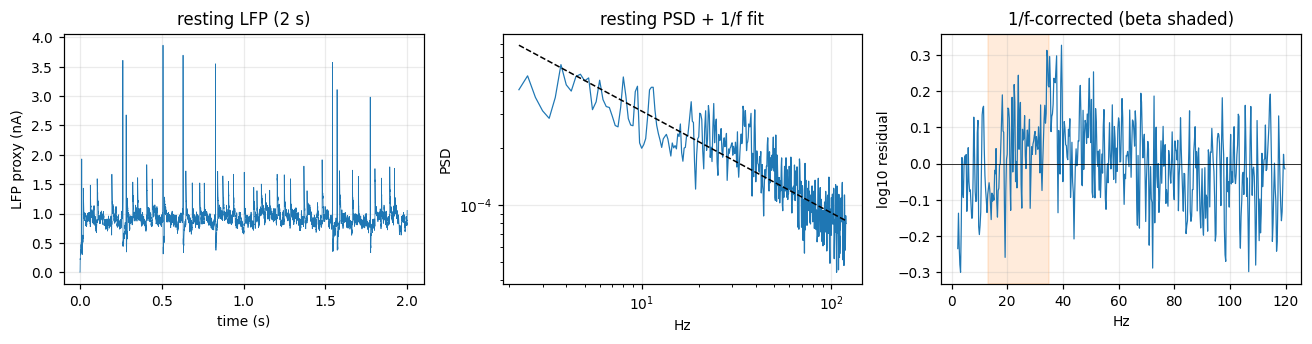

In [6]:
cfg = Cfg()
rest = simulate(cfg, 40.0)
print(f"E rate = {rest['rate_E']:.1f} Hz   I rate = {rest['rate_I']:.1f} Hz")

f, p = psd(rest['lfp'], rest['fs_lfp'], nperseg_s=4.)
k = (f > 2) & (f < 120)
fit = np.polyval(np.polyfit(np.log10(f[k]), np.log10(p[k]), 1), np.log10(f[k]))

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
ax[0].plot(rest['t'][:20000], rest['lfp'][:20000], lw=0.5)
ax[0].set(xlabel='time (s)', ylabel='LFP proxy (nA)', title='resting LFP (2 s)')
ax[1].loglog(f[k], p[k], lw=0.8); ax[1].loglog(f[k], 10**fit, 'k--', lw=1)
ax[1].set(xlabel='Hz', ylabel='PSD', title='resting PSD + 1/f fit')
ax[2].plot(f[k], np.log10(p[k]) - fit, lw=0.8); ax[2].axhline(0, c='k', lw=0.5)
ax[2].axvspan(13, 35, color='C1', alpha=0.15)
ax[2].set(xlabel='Hz', ylabel='log10 residual', title='1/f-corrected (beta shaded)')
plt.tight_layout(); plt.show()

## 6. Charting at 55 Hz — four conditions

The 2×2 that separates the hypotheses. Same neural simulation underneath where possible; what
changes is whether the neurons feel the stimulus and whether the chain is dirty.

| | neural coupling | chain |
|---|---|---|
| **A** | on | clean (no artifact, ideal ADC) — isolates **H1** |
| **B** | off (`gain_E=gain_I=0`) | dirty (clock + current-proportional artifact, alternation, real ADC) — isolates **H2/H3** |
| **C** | on | dirty — what you actually record |
| **D** | on | clean, but the stimulus itself is period-2 — a *real* neural response to an *artifactual* stimulus, the case that is easy to forget |

First, where the harmonics land after sampling at 250 Hz.

In [7]:
alias_table(55.)
print()
alias_table(80.)

f_stim=55.0 Hz, ADC=250.0 Hz (Nyquist 125.0), device LP=450.0 Hz
 component   true Hz  observed Hz   folded
      1*fs      55.0         55.0   
    0.5*fs      27.5         27.5   
      2*fs     110.0        110.0   
    1.5*fs      82.5         82.5   
      3*fs     165.0         85.0   YES
    2.5*fs     137.5        112.5   YES
      4*fs     220.0         30.0   YES
    3.5*fs     192.5         57.5   YES
      5*fs     275.0         25.0   YES
    4.5*fs     247.5          2.5   YES
      6*fs     330.0         80.0   YES
    5.5*fs     302.5         52.5   YES

f_stim=80.0 Hz, ADC=250.0 Hz (Nyquist 125.0), device LP=450.0 Hz
 component   true Hz  observed Hz   folded
      1*fs      80.0         80.0   
    0.5*fs      40.0         40.0   
      2*fs     160.0         90.0   YES
    1.5*fs     120.0        120.0   
      3*fs     240.0         10.0   YES
    2.5*fs     200.0         50.0   YES
      4*fs     320.0         70.0   YES
    3.5*fs     280.0         30.0   YES
    

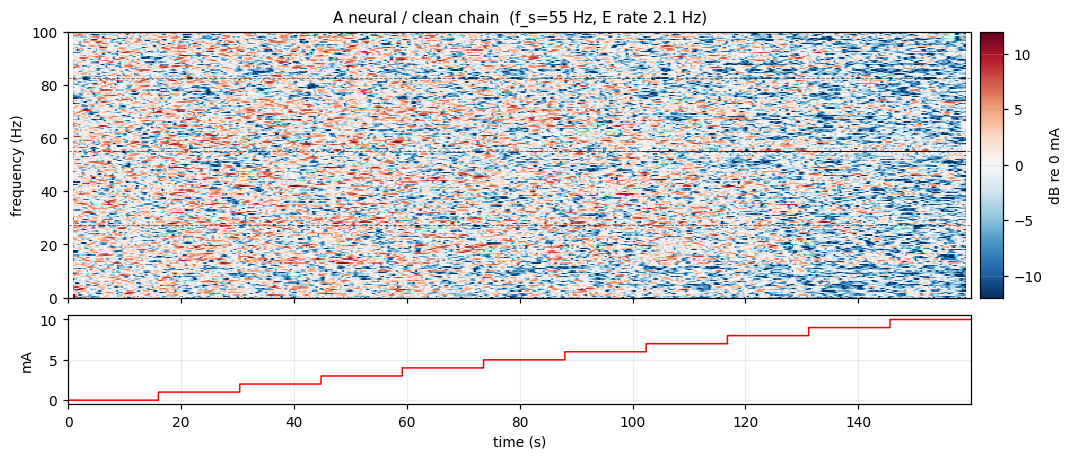

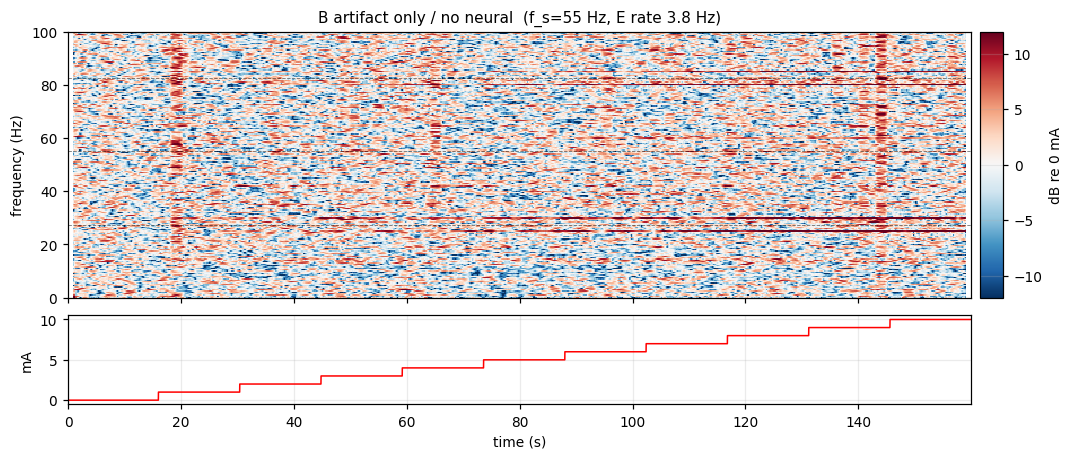

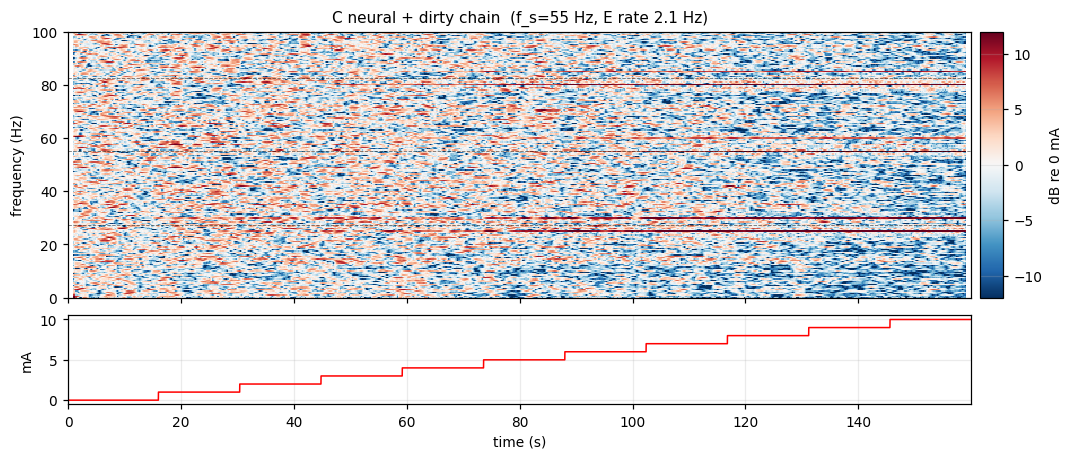

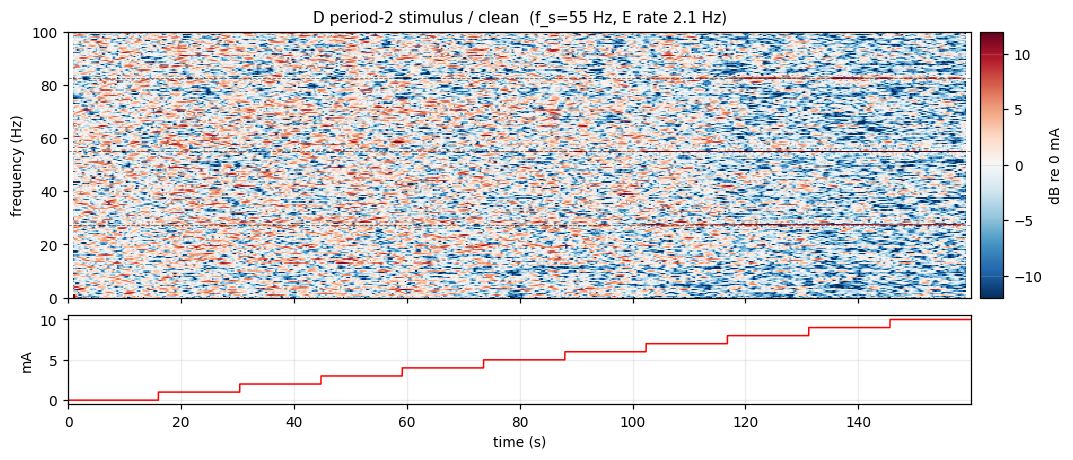

In [8]:
DUR, A_MAX, N_STEP = 160., 10., 10
sched = lambda t: staircase(t, DUR, a_max=A_MAX, n_steps=N_STEP)
FS_ADC = 250.

def charting(f_stim, neural=True, dirty=True, alternation=0.0, jitter=0.0,
             saturation=0.0, ideal_adc=False, cfg=cfg, dur=DUR):
    c = replace(cfg, gain_E=cfg.gain_E if neural else 0.0,
                     gain_I=cfg.gain_I if neural else 0.0)
    st = Stim(f_stim=f_stim, amp=1.0, alternation=alternation, jitter=jitter)
    sim = simulate(c, dur, st, sched)
    t, x = record(sim, FS_ADC,
                  artifact_gain=fundamental_gain(0.02, st) if dirty else 0.0,
                  clock_gain=fundamental_gain(0.01, st) if dirty else 0.0,
                  saturation=saturation, ideal_adc=ideal_adc or not dirty)
    amp_t = sched(t)
    return sim, t, x, amp_t


runs = {}
runs['A neural / clean chain']     = charting(55., neural=True,  dirty=False, saturation=0.0)
runs['B artifact only / no neural'] = charting(55., neural=False, dirty=True,  alternation=0.03)
runs['C neural + dirty chain']      = charting(55., neural=True,  dirty=True,  alternation=0.03,
                                               saturation=0.6)
runs['D period-2 stimulus / clean'] = charting(55., neural=True,  dirty=False, alternation=0.15)

for name, (sim, t, x, amp_t) in runs.items():
    plot_charting(t, x, FS_ADC, amp_t,
                  title=f'{name}  (f_s=55 Hz, E rate {sim["rate_E"]:.1f} Hz)',
                  f_marks=(27.5, 55., 82.5), baseline_s=0.1*DUR)
    plt.show()

### 6.1 Amplitude profiles

The discriminator. A genuine Arnold tongue has a **threshold and an upper boundary** — 1:2
entrainment is lost when amplitude is pushed past the top of the tongue (Sermon et al. saw
exactly this in all three patients at 150 Hz). An artifact just keeps growing.

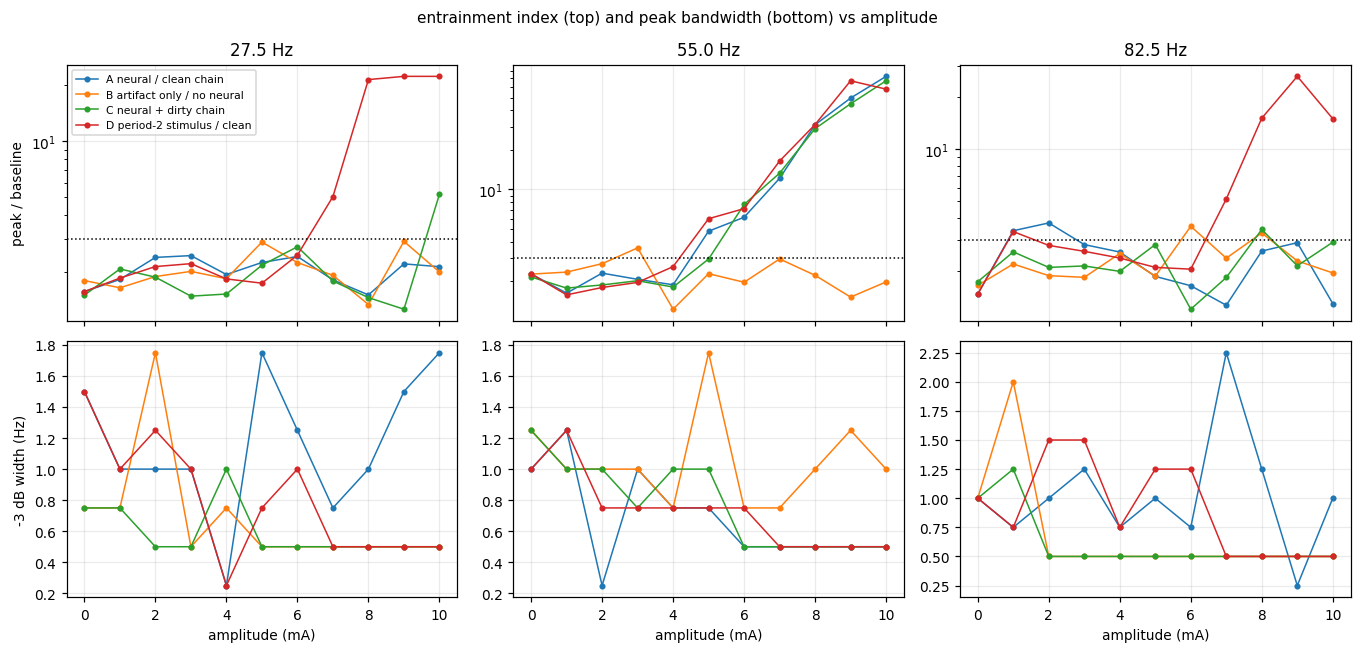

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(12.5, 6), sharex=True)
for j, f0 in enumerate([27.5, 55.0, 82.5]):
    for name, (sim, t, x, amp_t) in runs.items():
        steps = step_psds(x, FS_ADC, amp_t)
        a, idx, bw = profile(steps, f0)
        ax[0, j].plot(a, idx, 'o-', ms=3, lw=1, label=name)
        ax[1, j].plot(a, bw, 'o-', ms=3, lw=1)
    ax[0, j].axhline(3, c='k', ls=':', lw=1)
    ax[0, j].set(title=f'{f0} Hz', yscale='log', ylabel='peak / baseline' if j == 0 else '')
    ax[1, j].set(xlabel='amplitude (mA)', ylabel='-3 dB width (Hz)' if j == 0 else '')
ax[0, 0].legend(fontsize=7)
plt.suptitle('entrainment index (top) and peak bandwidth (bottom) vs amplitude', fontsize=10)
plt.tight_layout(); plt.show()

### 6.2 Rotation number and E-cell saturation

**Read this plot carefully.** $R \approx f_0/f_s$ *always* — a 27 Hz rhythm under 55 Hz pulses
gives $R \approx 0.5$ whether or not anything is locked. The value is not the evidence; the
**plateau** is. Following Duchet et al. §4.2, locking means $|R-p/q|$ small *and* the smoothed
$\partial R/\partial f_0$ flat, i.e. $R$ stays pinned at 0.5 while the endogenous frequency is
varied. To test that here, sweep `I_dc_I` (which moves the resting peak) at fixed amplitude and
check whether $R$ tracks $f_0/f_s$ or sticks at 0.5.

The right panel is the honest one: E-cell rate vs amplitude, where depolarisation block shows up
as the HH cell *stopping* rather than firing faster.

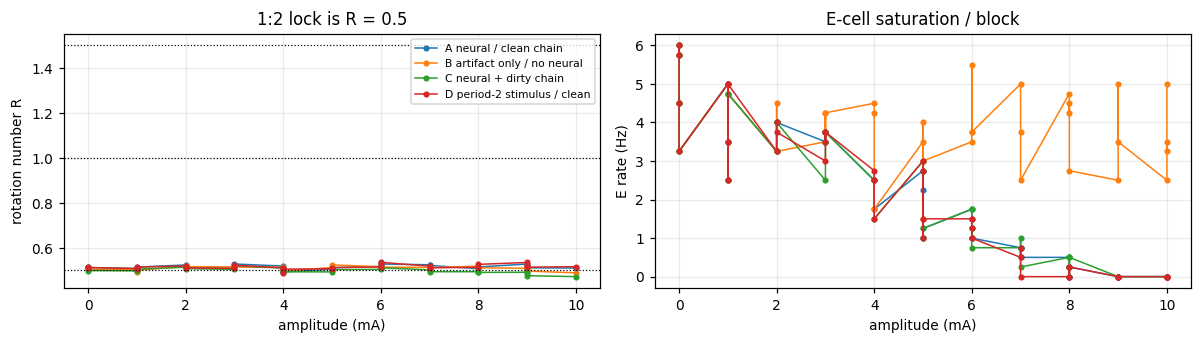

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for name, (sim, t, x, amp_t) in runs.items():
    a, R = rotation_windows(x, FS_ADC, sim['onsets'], band=(18., 40.), win=12.)
    ax[0].plot(sched(a), R, 'o-', ms=3, lw=1, label=name)
    tr, rr = spike_rate(sim, 'E', bin_s=4.)
    ax[1].plot(sched(tr), rr, 'o-', ms=3, lw=1)
for y in (0.5, 1.0, 1.5):
    ax[0].axhline(y, c='k', ls=':', lw=0.8)
ax[0].set(xlabel='amplitude (mA)', ylabel='rotation number R', title='1:2 lock is R = 0.5')
ax[1].set(xlabel='amplitude (mA)', ylabel='E rate (Hz)', title='E-cell saturation / block')
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 7. The decisive test — 80 Hz

Run the identical protocol at $f_s = 80$ Hz.

- Under **H2** (period-2 stimulus) the lines move rigidly to **40 and 120 Hz**. They must, because
  they are properties of the pulse train, not of the brain.
- Under **H1** they do not, because 40 Hz is off the resting rhythm: the 1:2 tongue is simply not
  reachable, and you should see 1:1 entrainment near 80 Hz instead (or nothing).

This is one clinic session and it settles the question. It is also the test Duchet et al.'s
framework tells you to run: tongue existence depends on where the *endogenous* rhythm sits
relative to $f_s/q$.

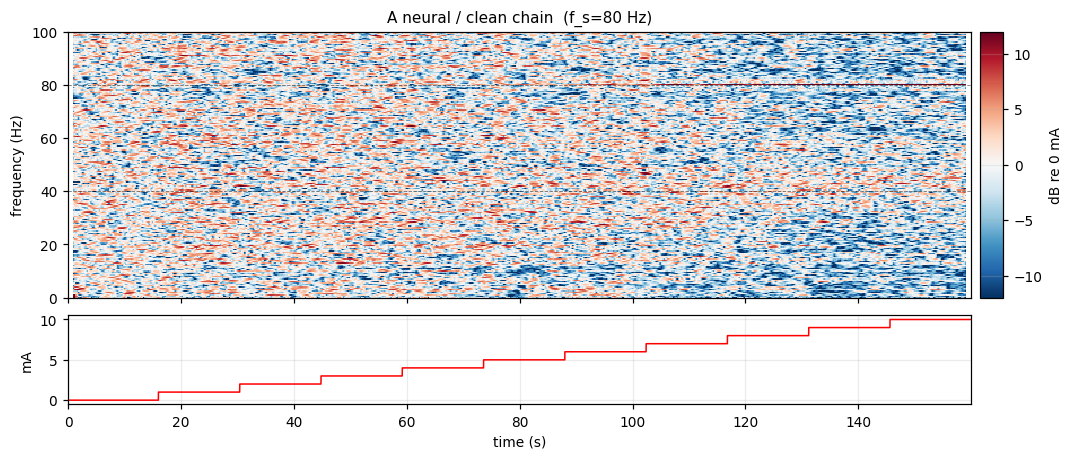

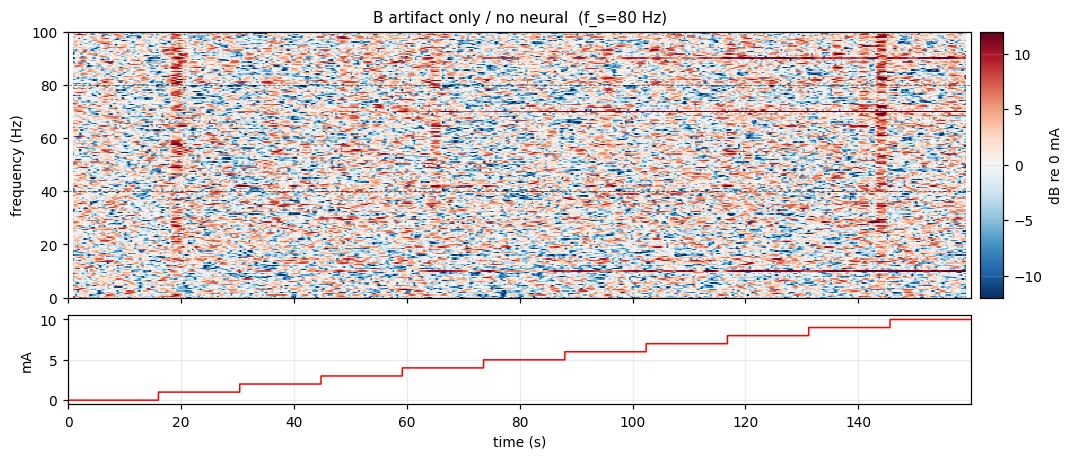

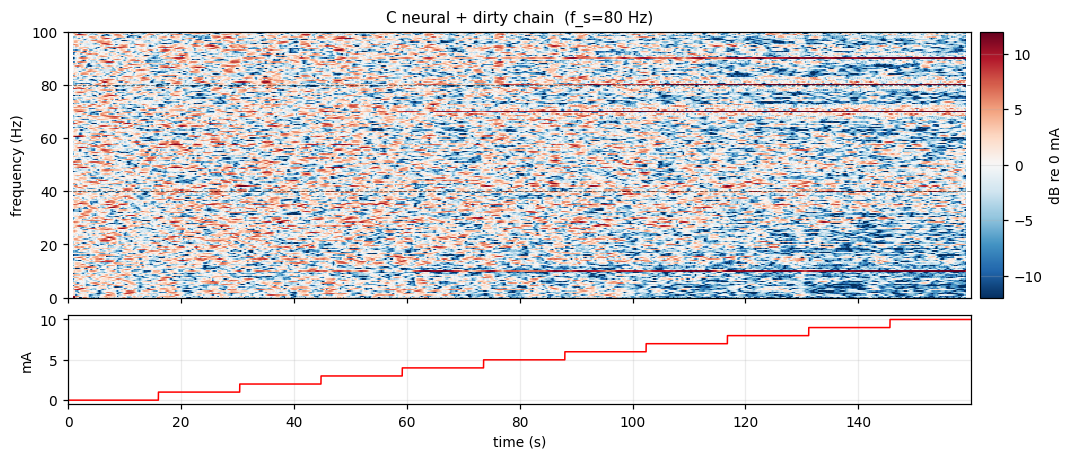

In [11]:
runs80 = {}
runs80['A neural / clean chain']      = charting(80., neural=True,  dirty=False)
runs80['B artifact only / no neural'] = charting(80., neural=False, dirty=True, alternation=0.03)
runs80['C neural + dirty chain']      = charting(80., neural=True,  dirty=True, alternation=0.03,
                                                 saturation=0.6)

for name, (sim, t, x, amp_t) in runs80.items():
    plot_charting(t, x, FS_ADC, amp_t, title=f'{name}  (f_s=80 Hz)',
                  f_marks=(40., 80., 120.), baseline_s=0.1*DUR)
    plt.show()

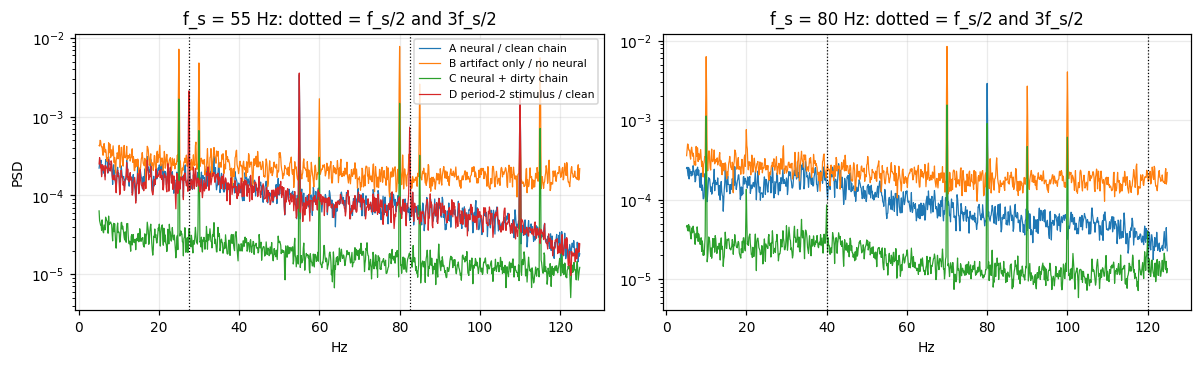

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for j, (lbl, rr, marks) in enumerate([('55 Hz', runs, (27.5, 82.5)),
                                      ('80 Hz', runs80, (40., 120.))]):
    for name, (sim, t, x, amp_t) in rr.items():
        f, p = psd(x[int(60*FS_ADC):], FS_ADC, nperseg_s=8.)
        k = (f > 5) & (f < 125)
        ax[j].semilogy(f[k], p[k], lw=0.8, label=name)
    for m in marks:
        ax[j].axvline(m, c='k', ls=':', lw=0.8)
    ax[j].set(xlabel='Hz', ylabel='PSD' if j == 0 else '',
              title=f'f_s = {lbl}: dotted = f_s/2 and 3f_s/2')
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 8. What to check in the patient data

Ordered by how cheap they are.

1. **Is the peak at 82.5 or 85.0 Hz?** One long Welch window answers it. 85.0 means the aliased
   3rd harmonic (H3) and nothing neural is involved. Same for 27.5 vs 30.0 Hz — note that the
   aliased 4th harmonic lands at 30 Hz, right on top of beta, which is its own problem for any
   beta biomarker measured during 55 Hz stimulation.
2. **Bandwidth.** Measure the −3 dB width of the 55 Hz line and of the 27.5 Hz line in the same
   window. If they are the same, both are device lines. If 27.5 Hz is several bins wider, it has
   neural phase noise in it.
3. **Amplitude profile.** Does the 27.5 Hz peak keep growing to 10 mA, or does it top out and
   fall? A tongue closes; an artifact does not.
4. **80 Hz session.** The rigid-shift test in §7.
5. **Hemisphere asymmetry.** From the slides, the side with a beta bump shows the subharmonics
   and the side without one does not. A device artifact should be bilateral and near-identical —
   same IPG, same telemetry. Worth confirming on the raw PSDs rather than from the photo.
6. **Calibrate the artifact from the 0 mA trace.** With the labels corrected, 0 mA gives you the
   clock leakage at zero delivered current. Subtract that spectrum from the on-stimulation ones
   before interpreting anything.

## Next step: the network

The hooks are already in `Cfg`: `r_E`, `r_I`, `r_ref`, and gain $\propto r_{\text{ref}}/r$. For the
network version, replace the two `NeuronGroup(1, ...)` calls with populations, draw positions,
set `stim_gain` per neuron from the monopole field, and connect with probability falling off in
distance. Everything downstream — the recording chain, the metrics, the charting plots — works
unchanged, because they only ever touch the LFP and the pulse times.

One honest caveat on the present version: with two neurons the "LFP" is one cell's synaptic
current, so it has the right shape but no amplitude calibration against mA. Tongue geometry and
the bandwidth discriminator survive that; absolute PSD comparisons against the patient data do
not until you have the network.